# CAFE paper assets — every table and figure as a PNG

Renders **Tables 1–10** and **Figures 1–5** of `CAFE_Hybrid_Manuscript.md` as images sized for
insertion into the `[TABLE n HERE]` / `[FIGURE n HERE]` placeholders in
`CAFE_Hybrid_TemplateFormat.docx`.

## Will the numbers change if I re-run this?

**No.** That is a property of how this notebook is built, and it is checked twice below rather
than asserted in prose:

1. **Nothing here fits a model.** Not one line trains CatBoost, XGBoost, the gate or Encoder B.
   Every number is *read* from the per-fold prediction files that the study scripts wrote on
   2026-07-22 and that are retained in `results/xmodal_study_2026-07-22/`. Re-running formats
   the same stored numbers again. Section 3 proves it: it re-renders everything and asserts the
   PNGs come out **byte-identical**.
2. **The numbers are checked against the manuscript.** Section 4 runs
   `verify_cafe_manuscript.py`, which recomputes ~163 quantities from those same CSVs and fails
   if any of them disagrees with what the paper says.

The one thing that *would* move the numbers is re-running the study scripts themselves
(`clinical_evaluation.py`, `xmodal_features.py`, `encoder_b_lightattention.py`) — those fit
models. This notebook never calls them.

Values are taken at full precision from the per-fold files, exactly as the verifier does, and
*not* from the rounded `*_summary.csv` — formatting an already-rounded value double-rounds it
and moves CatBoost's AUROC by one ulp (0.8515 → 0.852 instead of 0.851).

> All data are synthetic (`synthetic_generator_tuned.py`, `data/gen_hard`). No real patients.

## 1 · Setup and provenance of every source file

In [1]:
import hashlib
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path.cwd()
assert (REPO / "CAFE_Hybrid_Manuscript.md").exists(), (
    "Run this notebook from the repository root -- the scripts do sys.path.insert(0, ROOT)."
)
STUDY = REPO / "results" / "xmodal_study_2026-07-22"
FIGS = REPO / "figures" / "cafe"
TABLES = FIGS / "tables"

# The .py modules are the source of truth; this notebook imports them rather than
# reimplementing any of the rendering or any of the arithmetic.
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(STUDY))
import make_cafe_figures as mcf  # noqa: E402
import make_cafe_tables as mct  # noqa: E402


def sha(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]


SOURCES = [
    ("clinical_per_fold.csv", "Tables 3, 6, 7 -- 10 folds x 5 arms"),
    ("clinical_verdicts.csv", "Table 3 note -- decision-rule verdicts"),
    ("clinical_decision_curve.csv", "Table 6 -- net benefit by threshold"),
    ("clinical_operating_point.csv", "Table 7 -- 90 %-sensitivity threshold"),
    ("clinical_calibration_curve.csv", "Figure 1 -- reliability curves"),
    ("clinical_cost.csv", "Table 9, Figure 4 -- fit and inference time"),
    ("xmodal_per_fold.csv", "Tables 4, 10 -- feature-block ablation"),
    ("xmodal_verdicts.csv", "Table 4 -- sign agreement and verdicts"),
    ("encoder_b_per_fold.csv", "Tables 5, 10 -- Encoder B ablation"),
    ("encoder_b_verdicts.csv", "Table 5 -- verdicts"),
    ("hybrid_catboost_experts_per_fold.csv", "Tables 3, 10 -- the CAFE arm itself"),
    ("shap_global_importance.csv", "Table 8, Figure 3 -- out-of-fold TreeSHAP"),
]

prov = pd.DataFrame(
    [
        {
            "file": name,
            "rows": len(pd.read_csv(STUDY / name)),
            "written": pd.to_datetime((STUDY / name).stat().st_mtime, unit="s").strftime(
                "%Y-%m-%d %H:%M"
            ),
            "sha256": sha(STUDY / name),
            "feeds": what,
        }
        for name, what in SOURCES
    ]
)
print(f"{len(prov)} retained result files -- none of them is regenerated by this notebook\n")
prov

12 retained result files -- none of them is regenerated by this notebook



,file,rows,written,sha256,feeds
0,clinical_per_fold.csv,50,2026-07-22 15:14,3f3d01b53540,"Tables 3, 6, 7 -- 10 folds x 5 arms"
1,clinical_verdicts.csv,8,2026-07-22 15:14,a5a2443d864b,Table 3 note -- decision-rule verdicts
2,clinical_decision_curve.csv,46,2026-07-22 15:14,b2184b3a305f,Table 6 -- net benefit by threshold
3,clinical_operating_point.csv,5,2026-07-22 15:14,59119d5a57f8,Table 7 -- 90 %-sensitivity threshold
4,clinical_calibration_curve.csv,50,2026-07-22 15:14,be0062b2b890,Figure 1 -- reliability curves
5,clinical_cost.csv,5,2026-07-22 15:16,dcf2b4258bf1,"Table 9, Figure 4 -- fit and inference time"
6,xmodal_per_fold.csv,90,2026-07-22 07:22,ba3b361a0d88,"Tables 4, 10 -- feature-block ablation"
7,xmodal_verdicts.csv,8,2026-07-22 07:22,7c1d0de01e4c,Table 4 -- sign agreement and verdicts
8,encoder_b_per_fold.csv,50,2026-07-22 09:27,b15264633d6c,"Tables 5, 10 -- Encoder B ablation"
9,encoder_b_verdicts.csv,3,2026-07-22 09:27,ab5e57eb90d7,Table 5 -- verdicts


## 2 · Render the assets

### 2.1 Tables 1–10

Booktabs style, 300 dpi, caption above and source note below — matching
`scripts/make_paper_assets.py`, which produced the other paper's table images.

**[TABLE 1 HERE]** &rarr; `figures\cafe\tables\table01_feature_families.png`

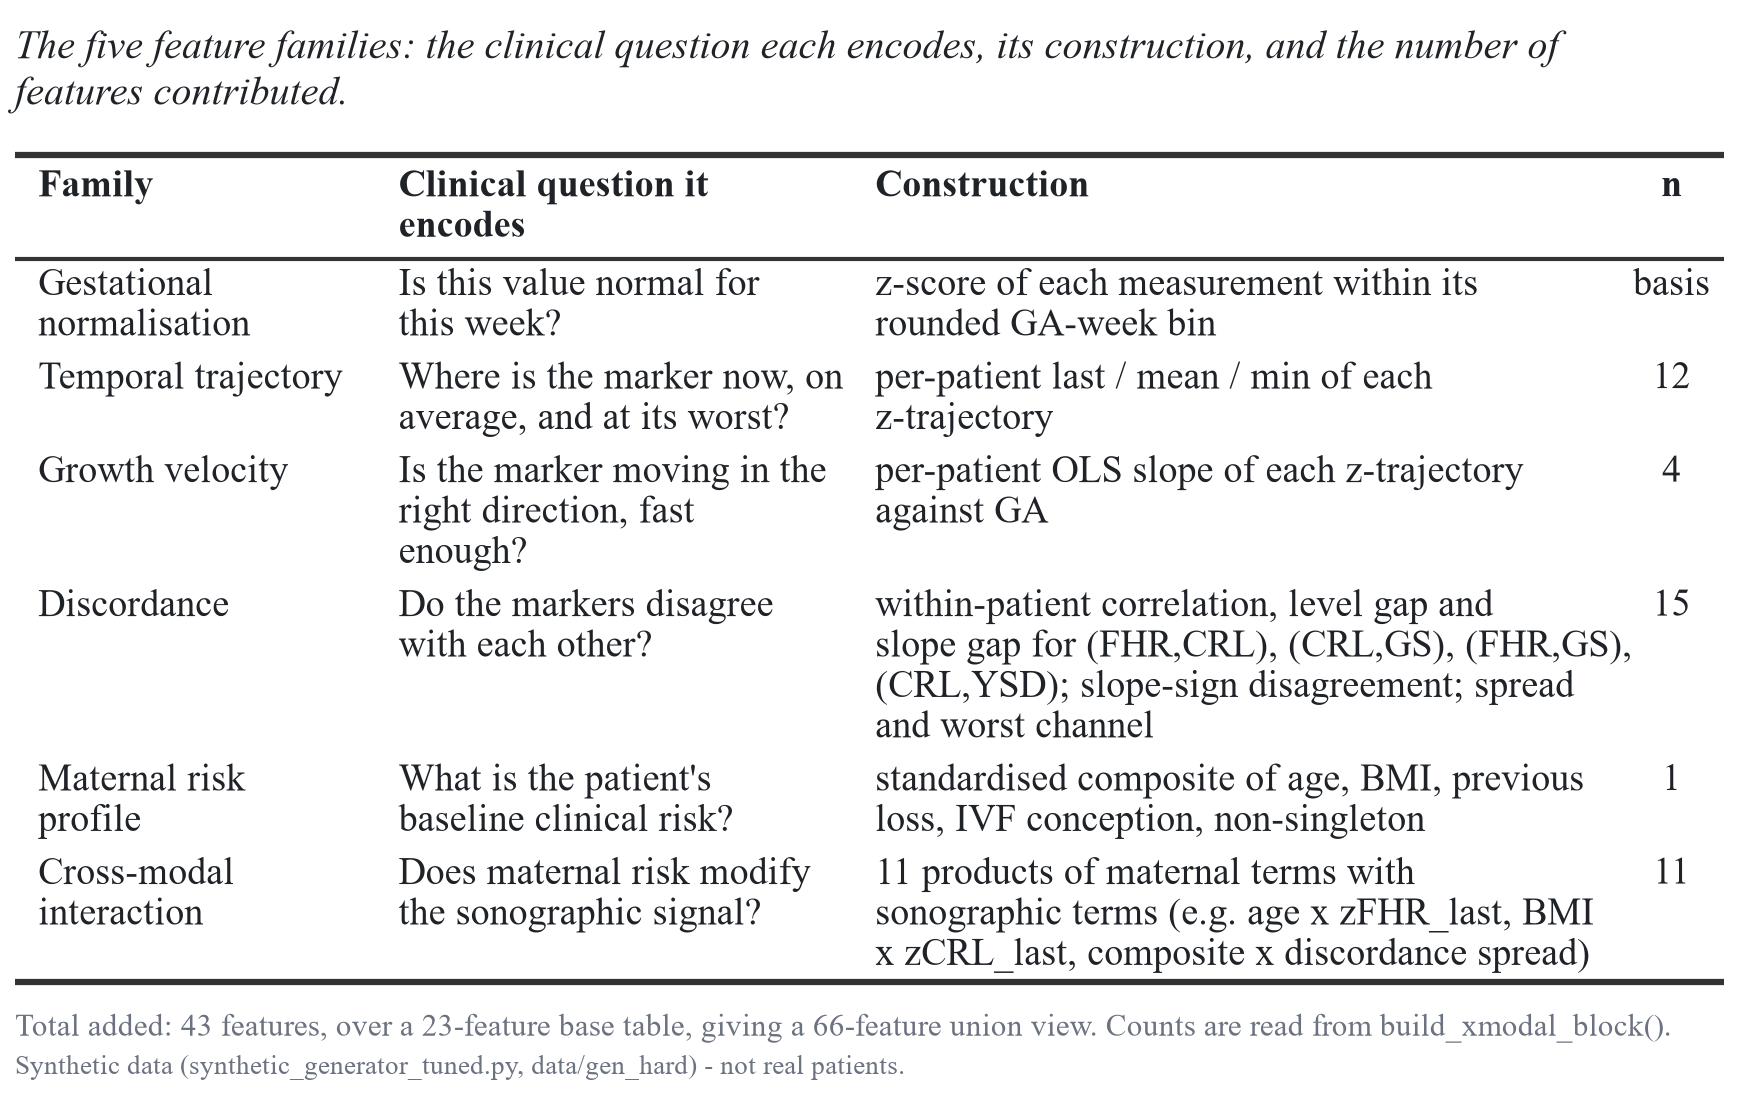

**[TABLE 2 HERE]** &rarr; `figures\cafe\tables\table02_encoder_specs.png`

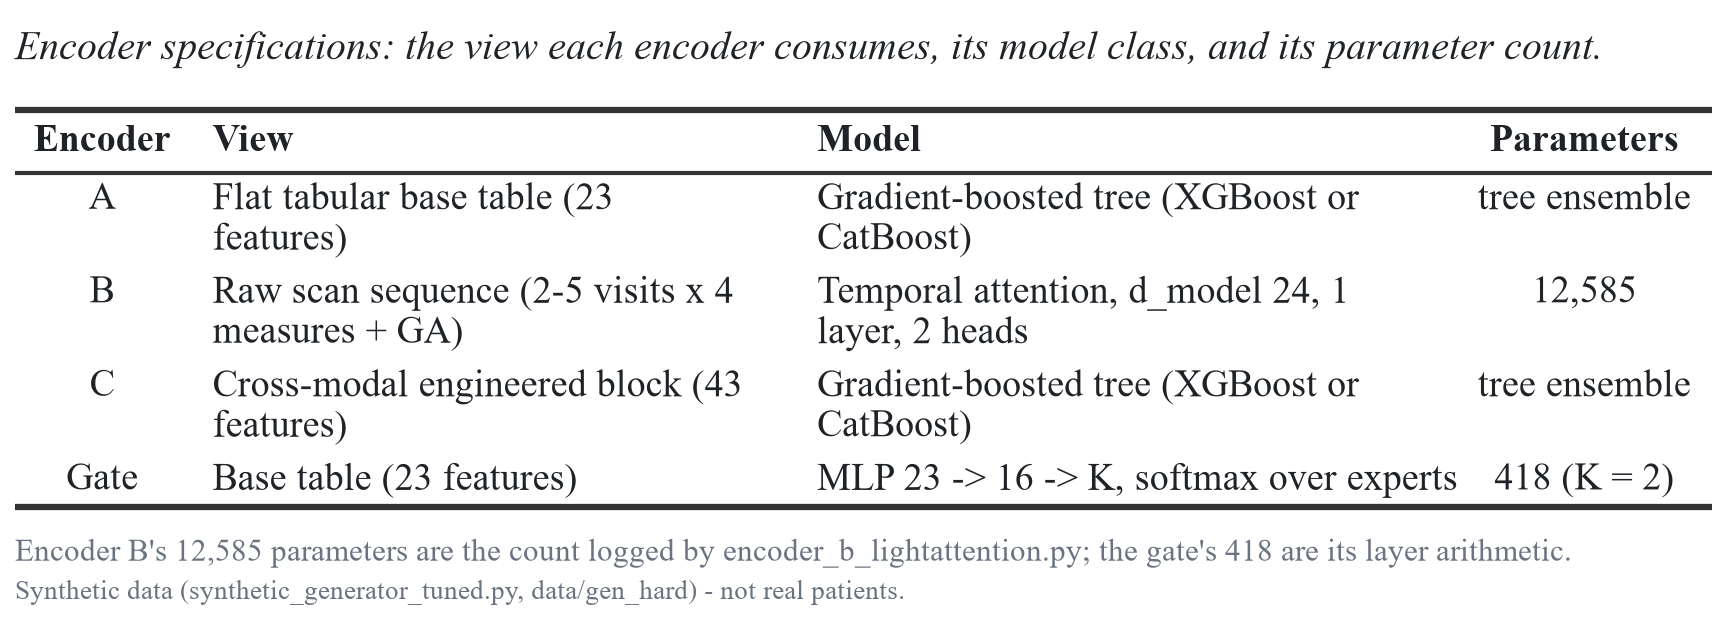

**[TABLE 3 HERE]** &rarr; `figures\cafe\tables\table03_discrimination_calibration.png`

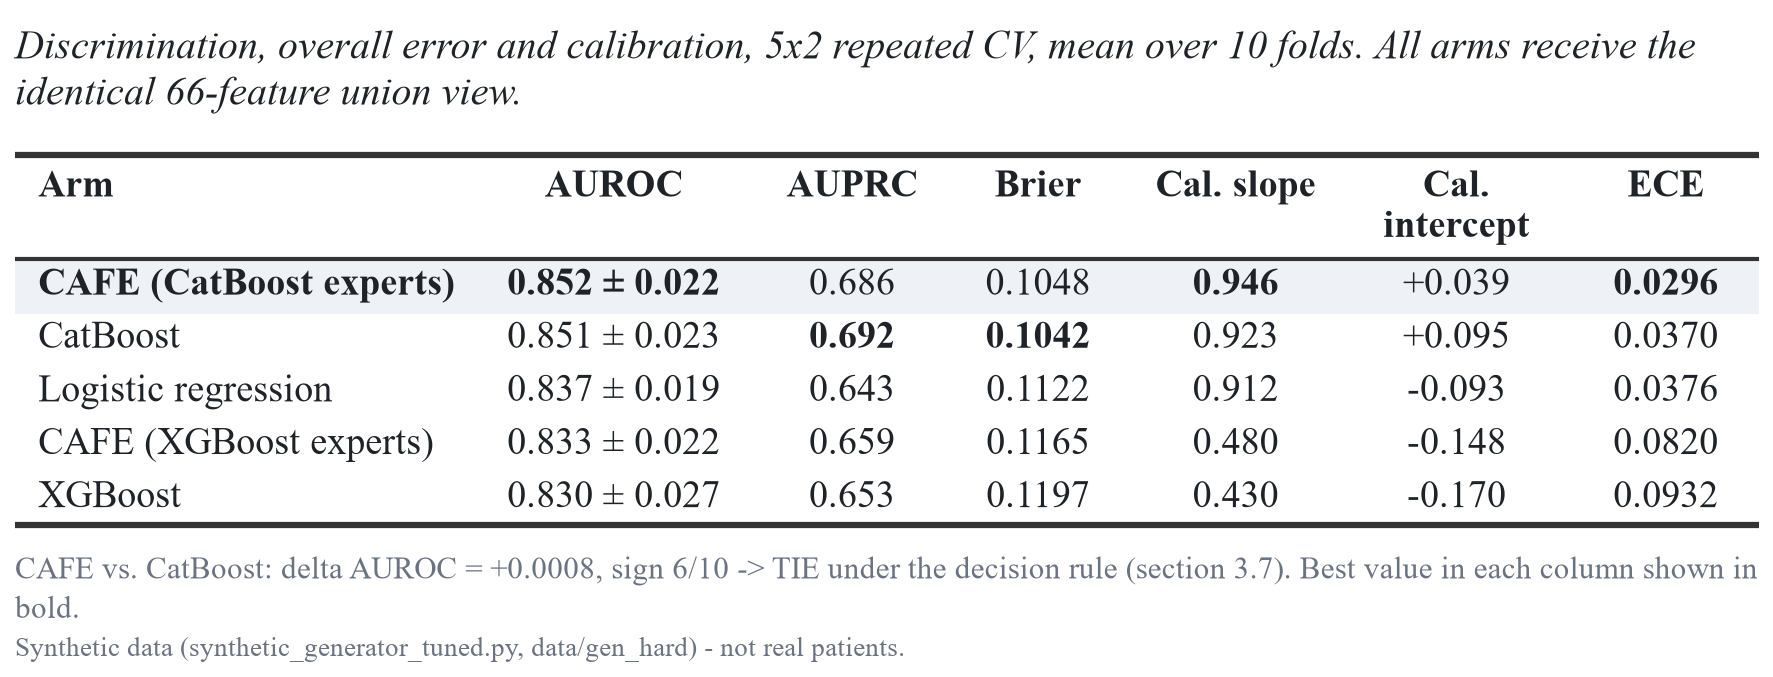

**[TABLE 4 HERE]** &rarr; `figures\cafe\tables\table04_engineered_features_by_learner.png`

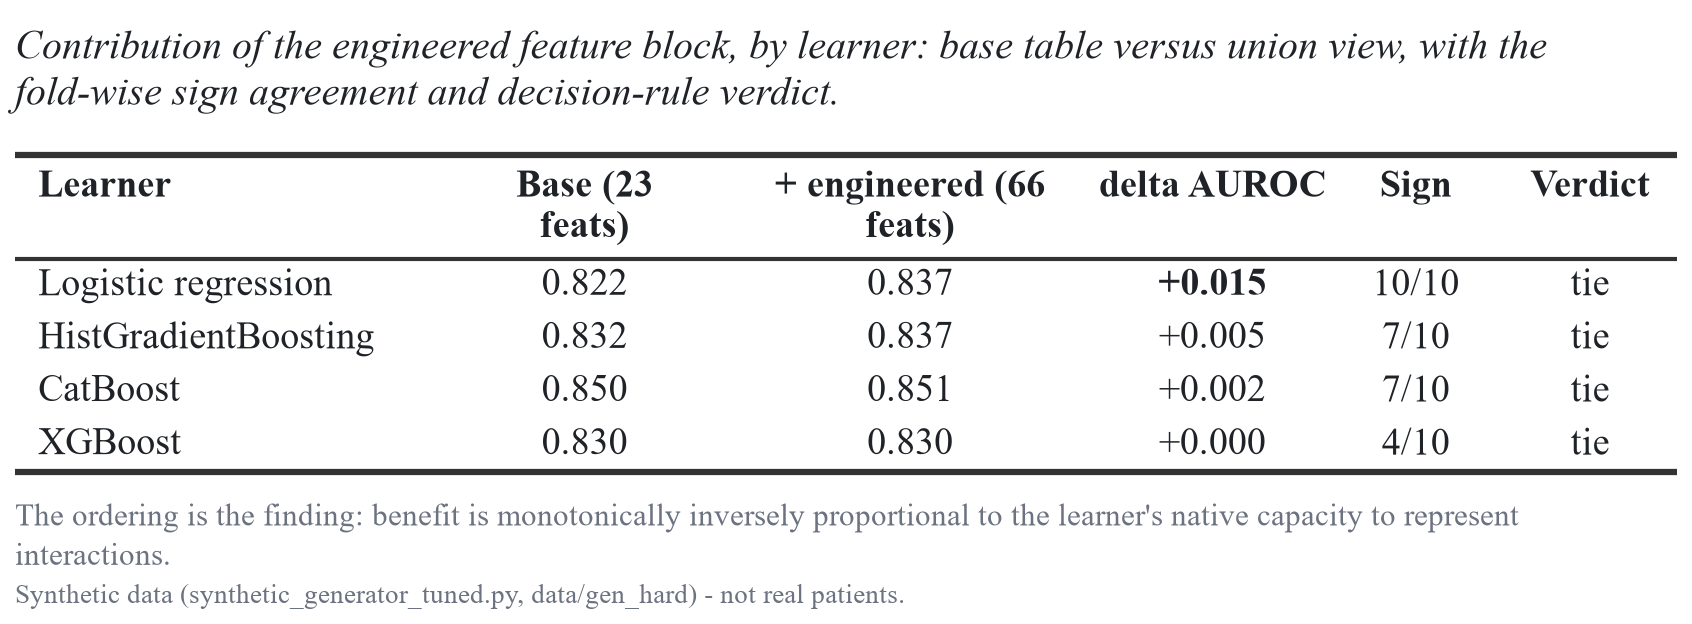

**[TABLE 5 HERE]** &rarr; `figures\cafe\tables\table05_encoder_b_ablation.png`

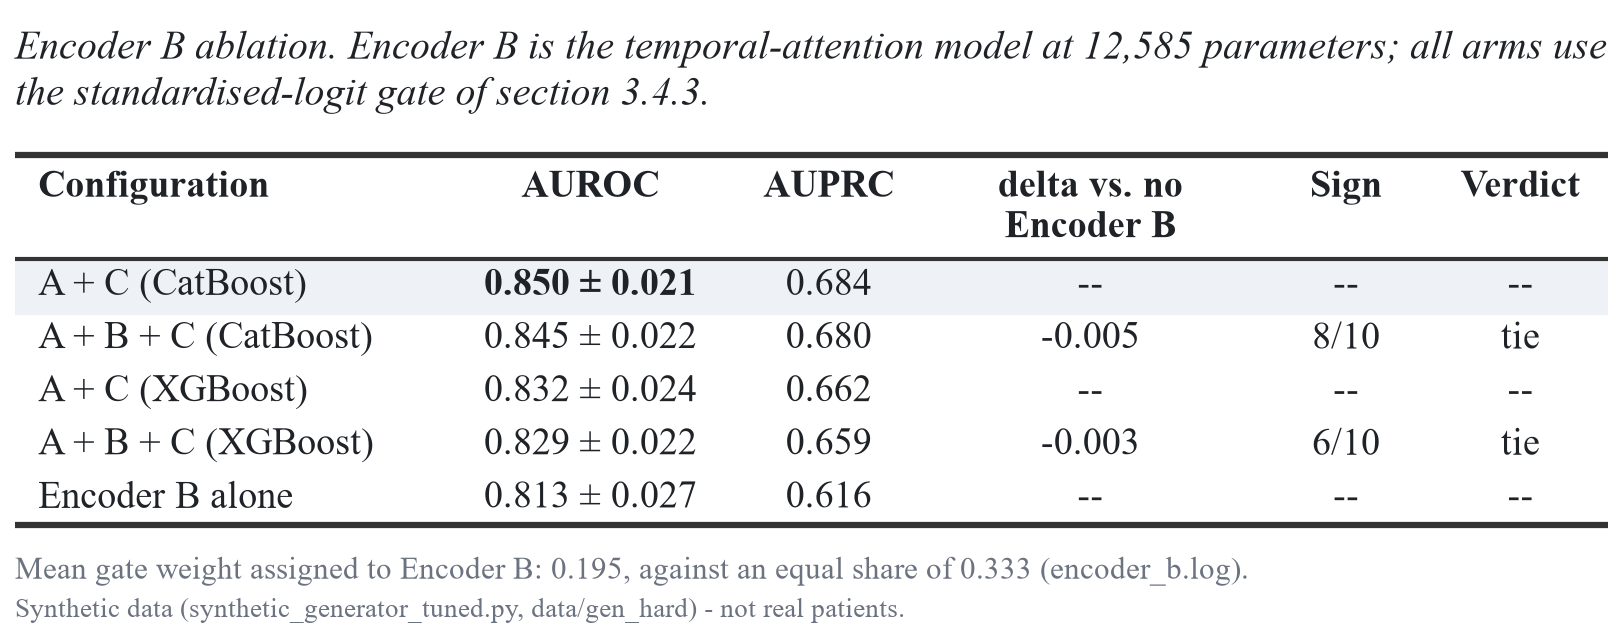

**[TABLE 6 HERE]** &rarr; `figures\cafe\tables\table06_decision_curve.png`

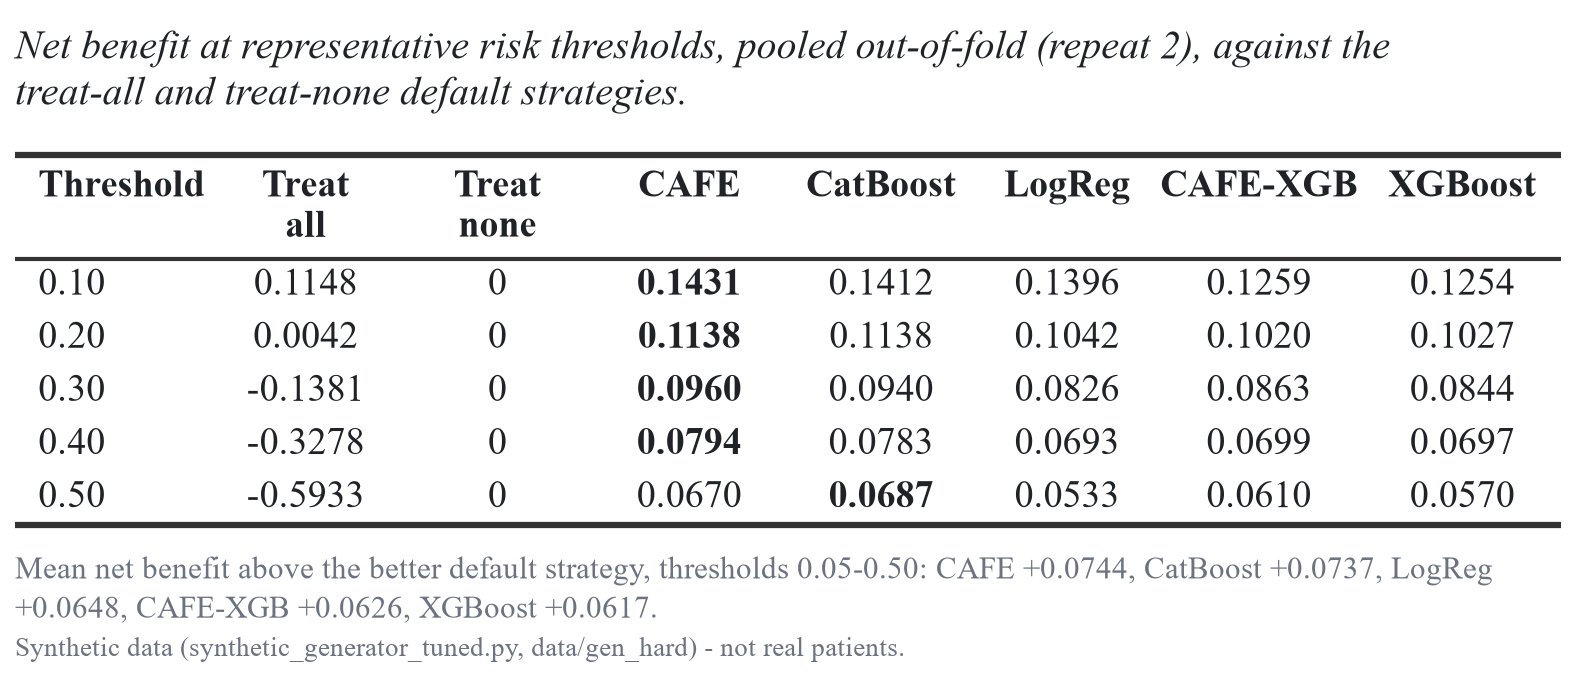

**[TABLE 7 HERE]** &rarr; `figures\cafe\tables\table07_operating_point.png`

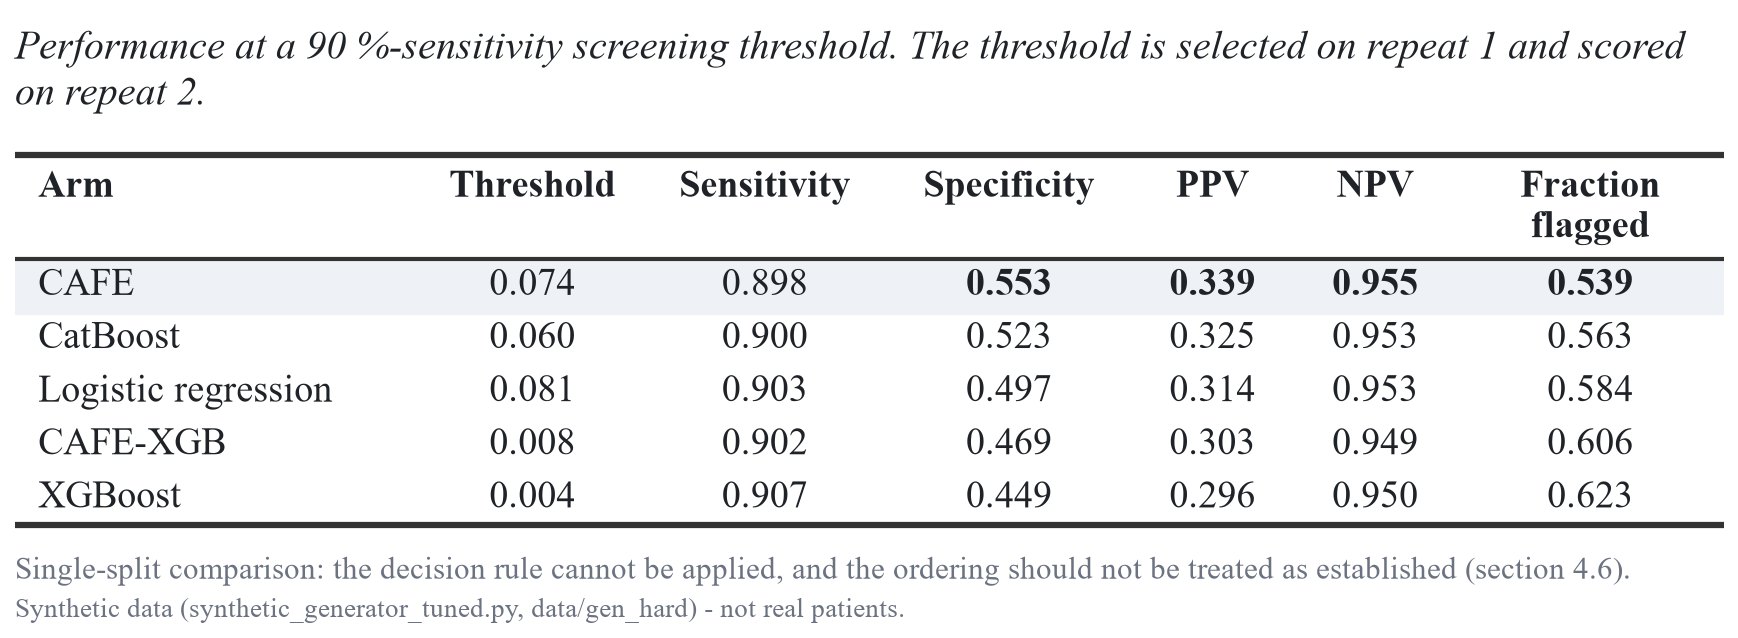

**[TABLE 8 HERE]** &rarr; `figures\cafe\tables\table08_shap_top15.png`

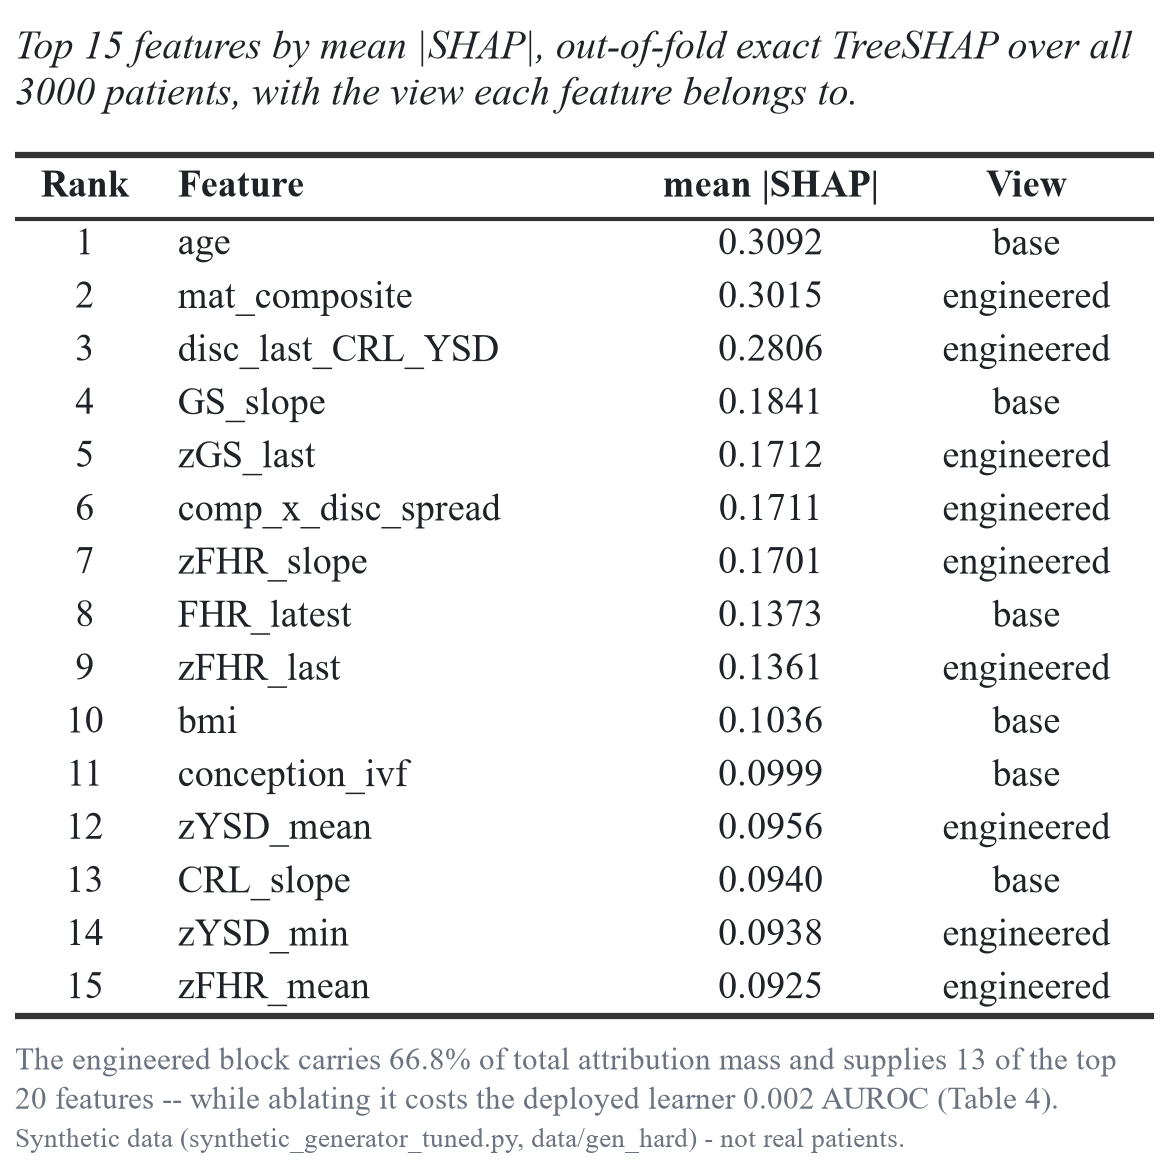

**[TABLE 9 HERE]** &rarr; `figures\cafe\tables\table09_cost.png`

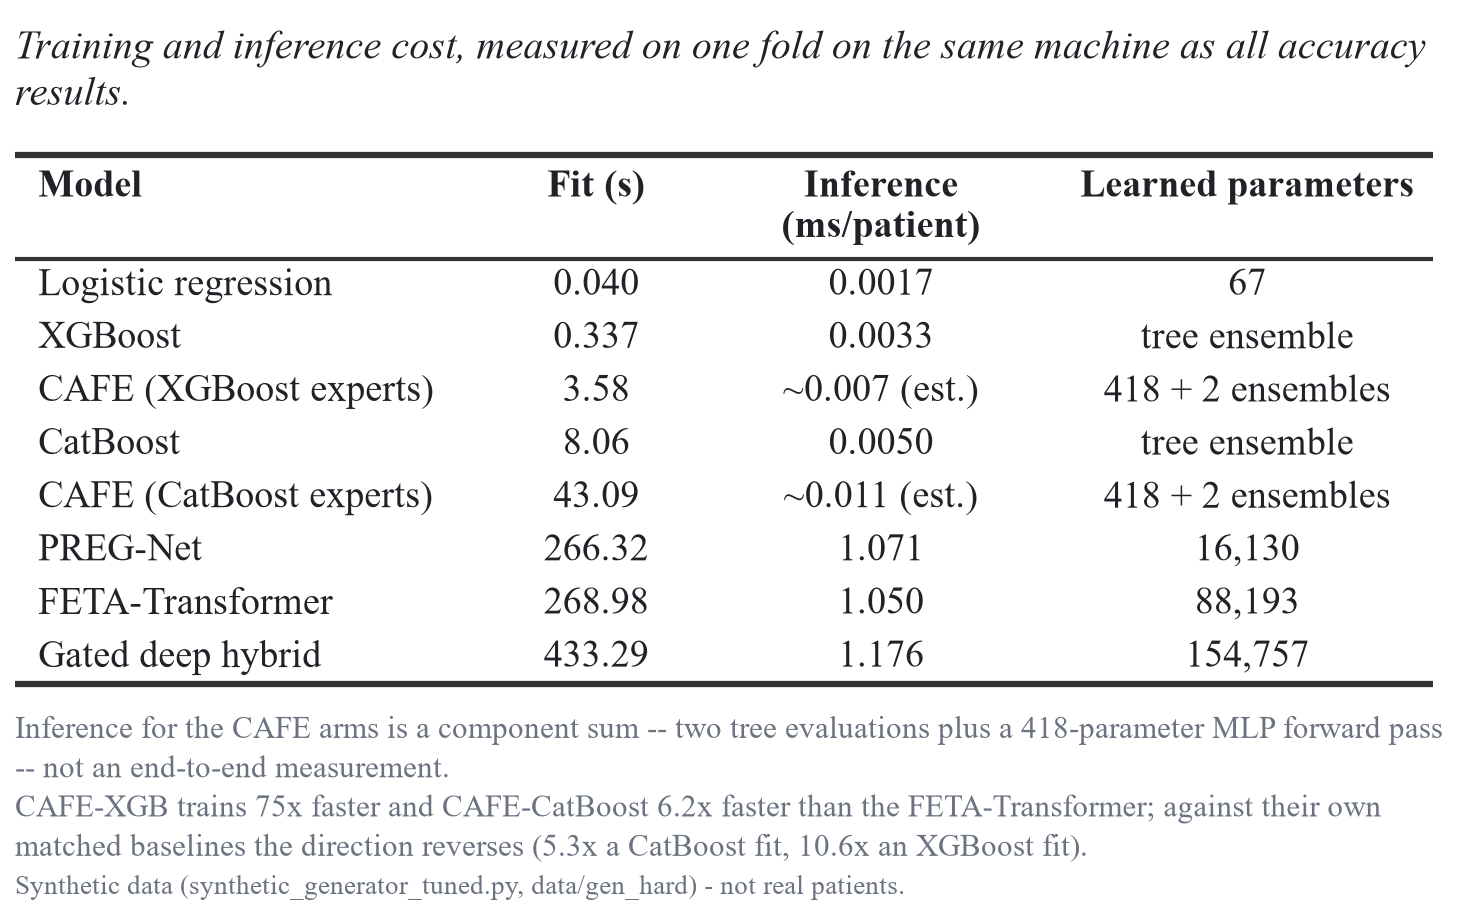

**[TABLE 10 HERE]** &rarr; `figures\cafe\tables\table10_ablation_decomposition.png`

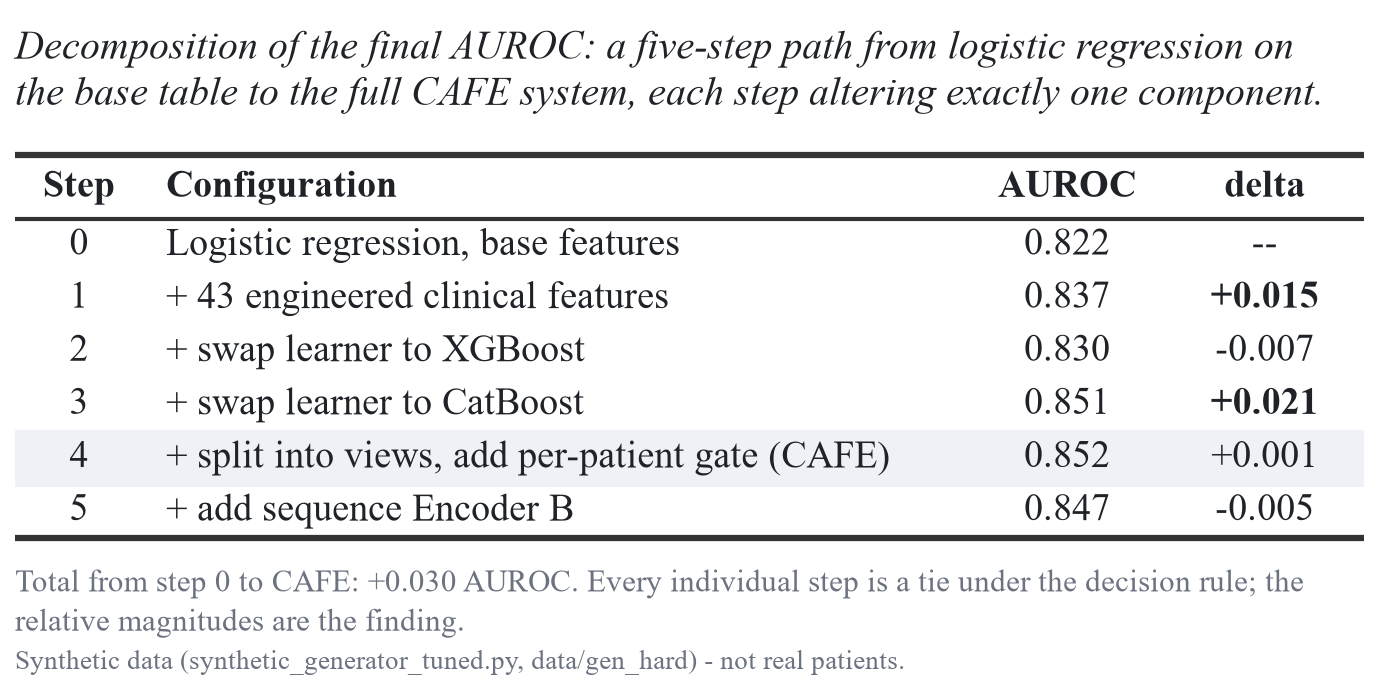

In [2]:
sources = mct.load()  # reads the CSVs above; fits nothing

table_paths = {}
for n, build in enumerate(mct.BUILDERS, start=1):
    table_paths[n] = build(sources)

for n, path in table_paths.items():
    display(Markdown(f"**[TABLE {n} HERE]** &rarr; `{path.relative_to(REPO)}`"))
    display(Image(filename=str(path), width=900))

### 2.2 Figures 1–5

**[FIGURE 1 HERE]** &rarr; `figures\cafe\fig_cafe_calibration.png`

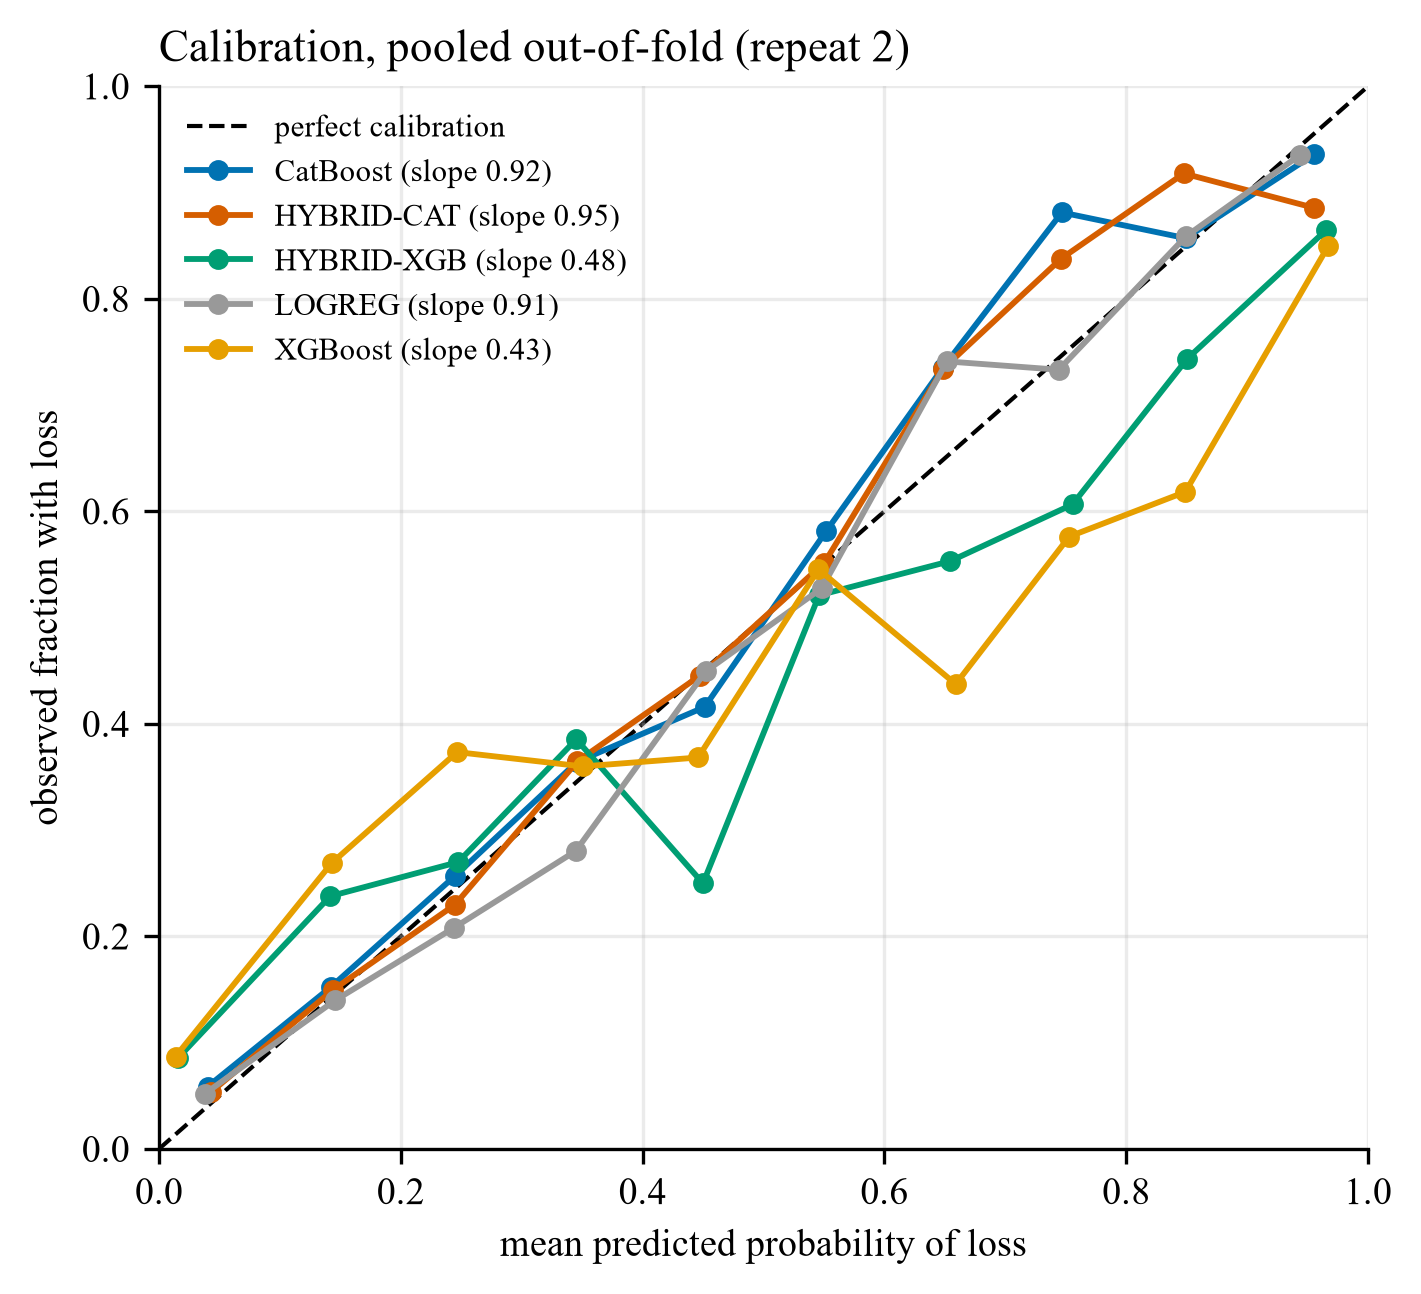

**[FIGURE 2 HERE]** &rarr; `figures\cafe\fig_cafe_decision_curve.png`

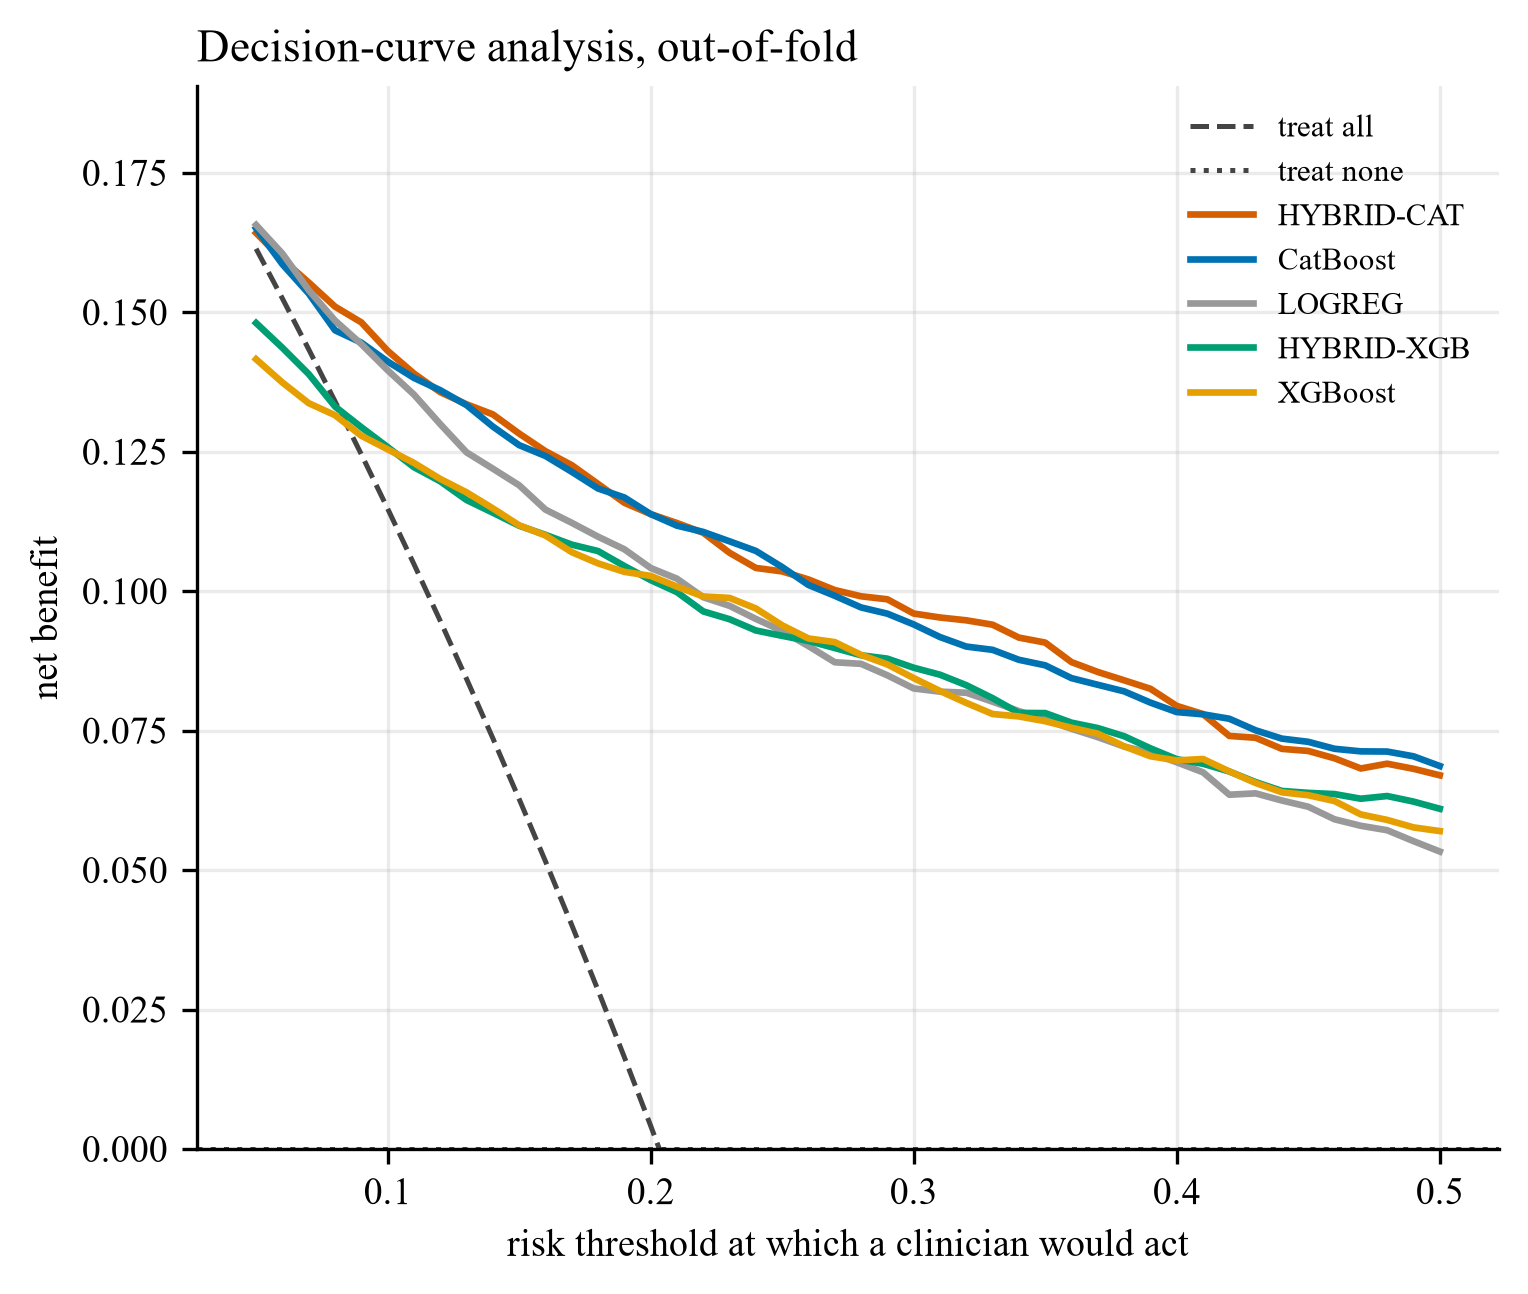

**[FIGURE 3 HERE]** &rarr; `figures\cafe\fig_cafe_shap.png`

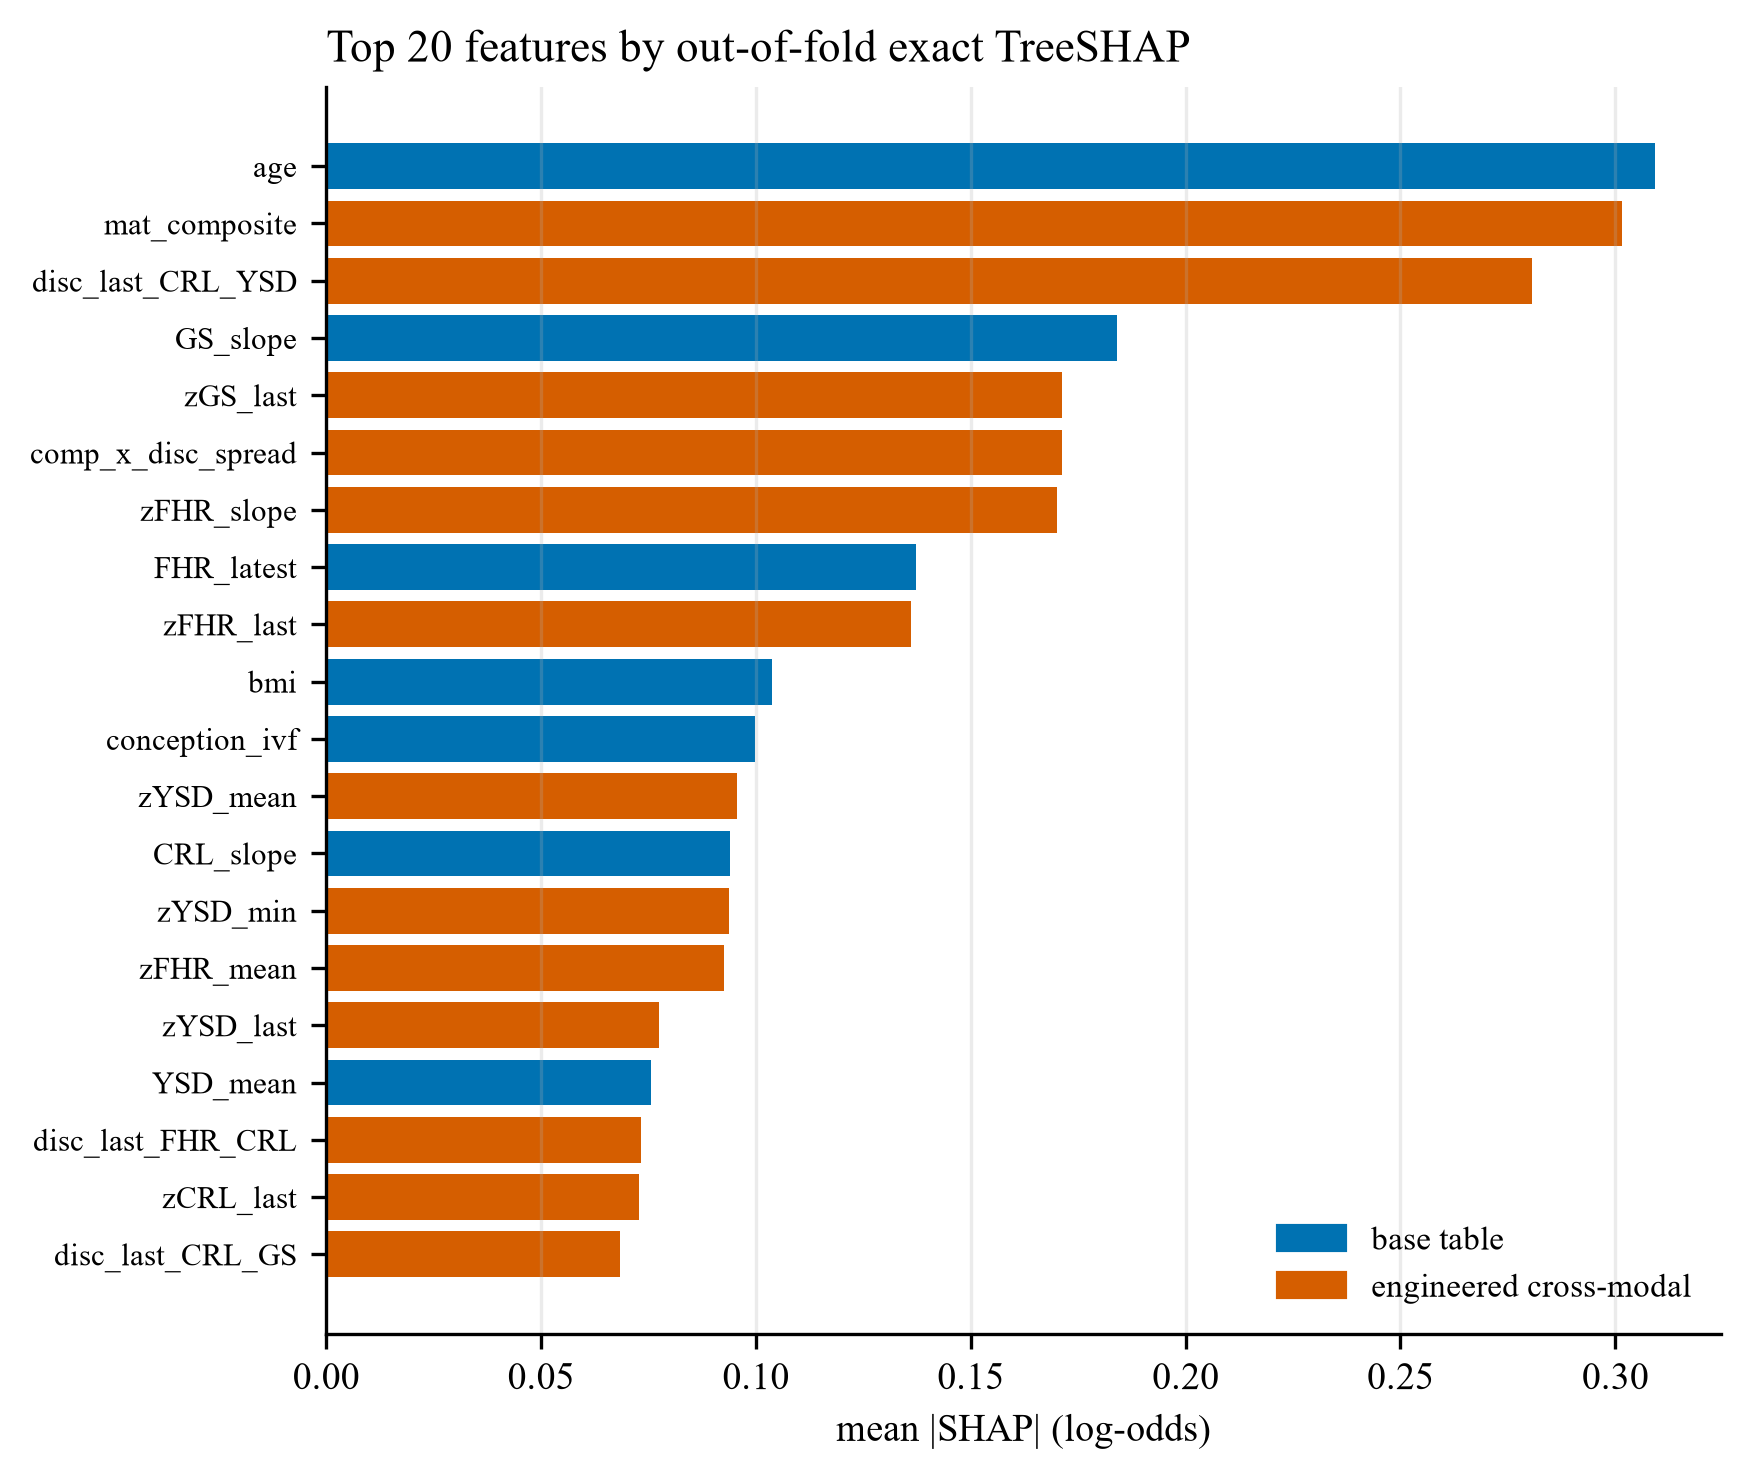

**[FIGURE 4 HERE]** &rarr; `figures\cafe\fig_cafe_accuracy_vs_cost.png`

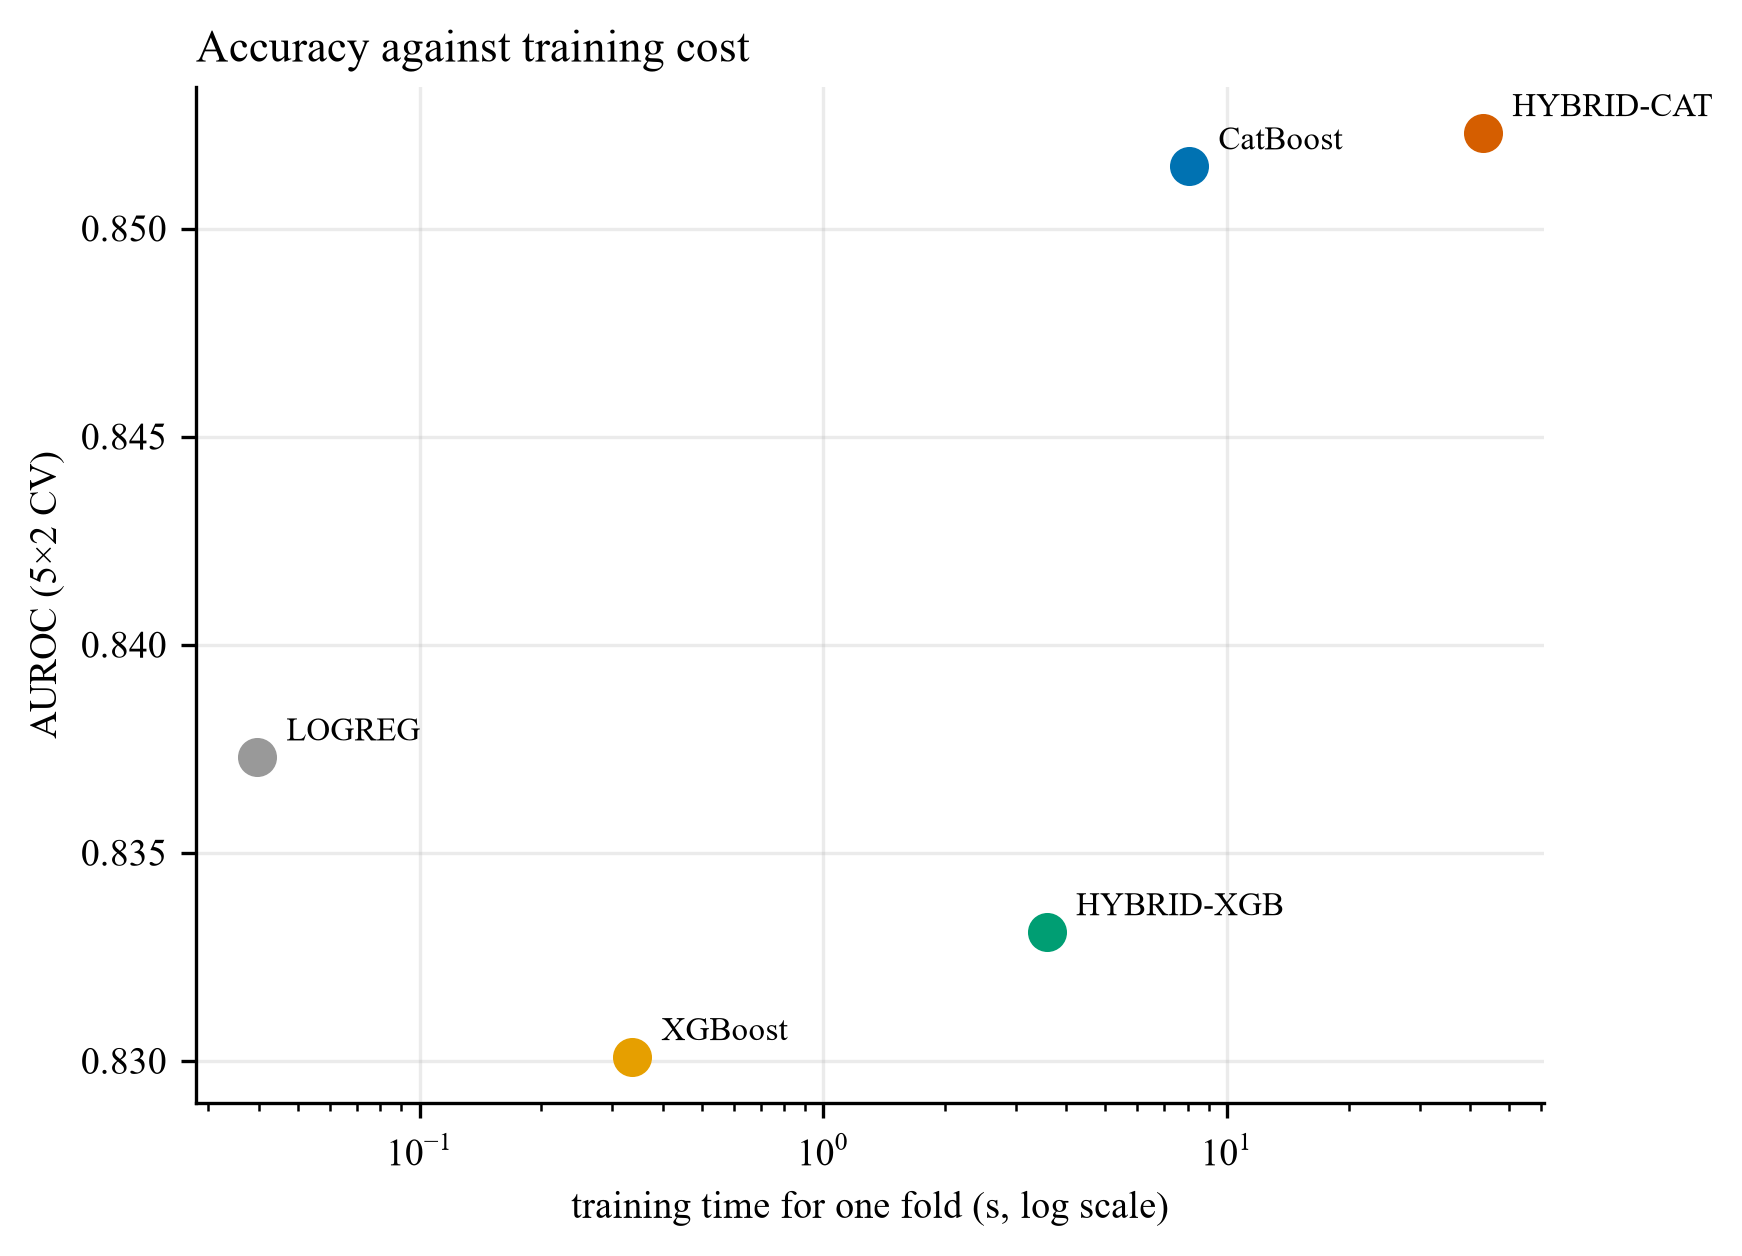

**[FIGURE 5 HERE]** &rarr; `figures\cafe\fig_cafe_ablation.png`

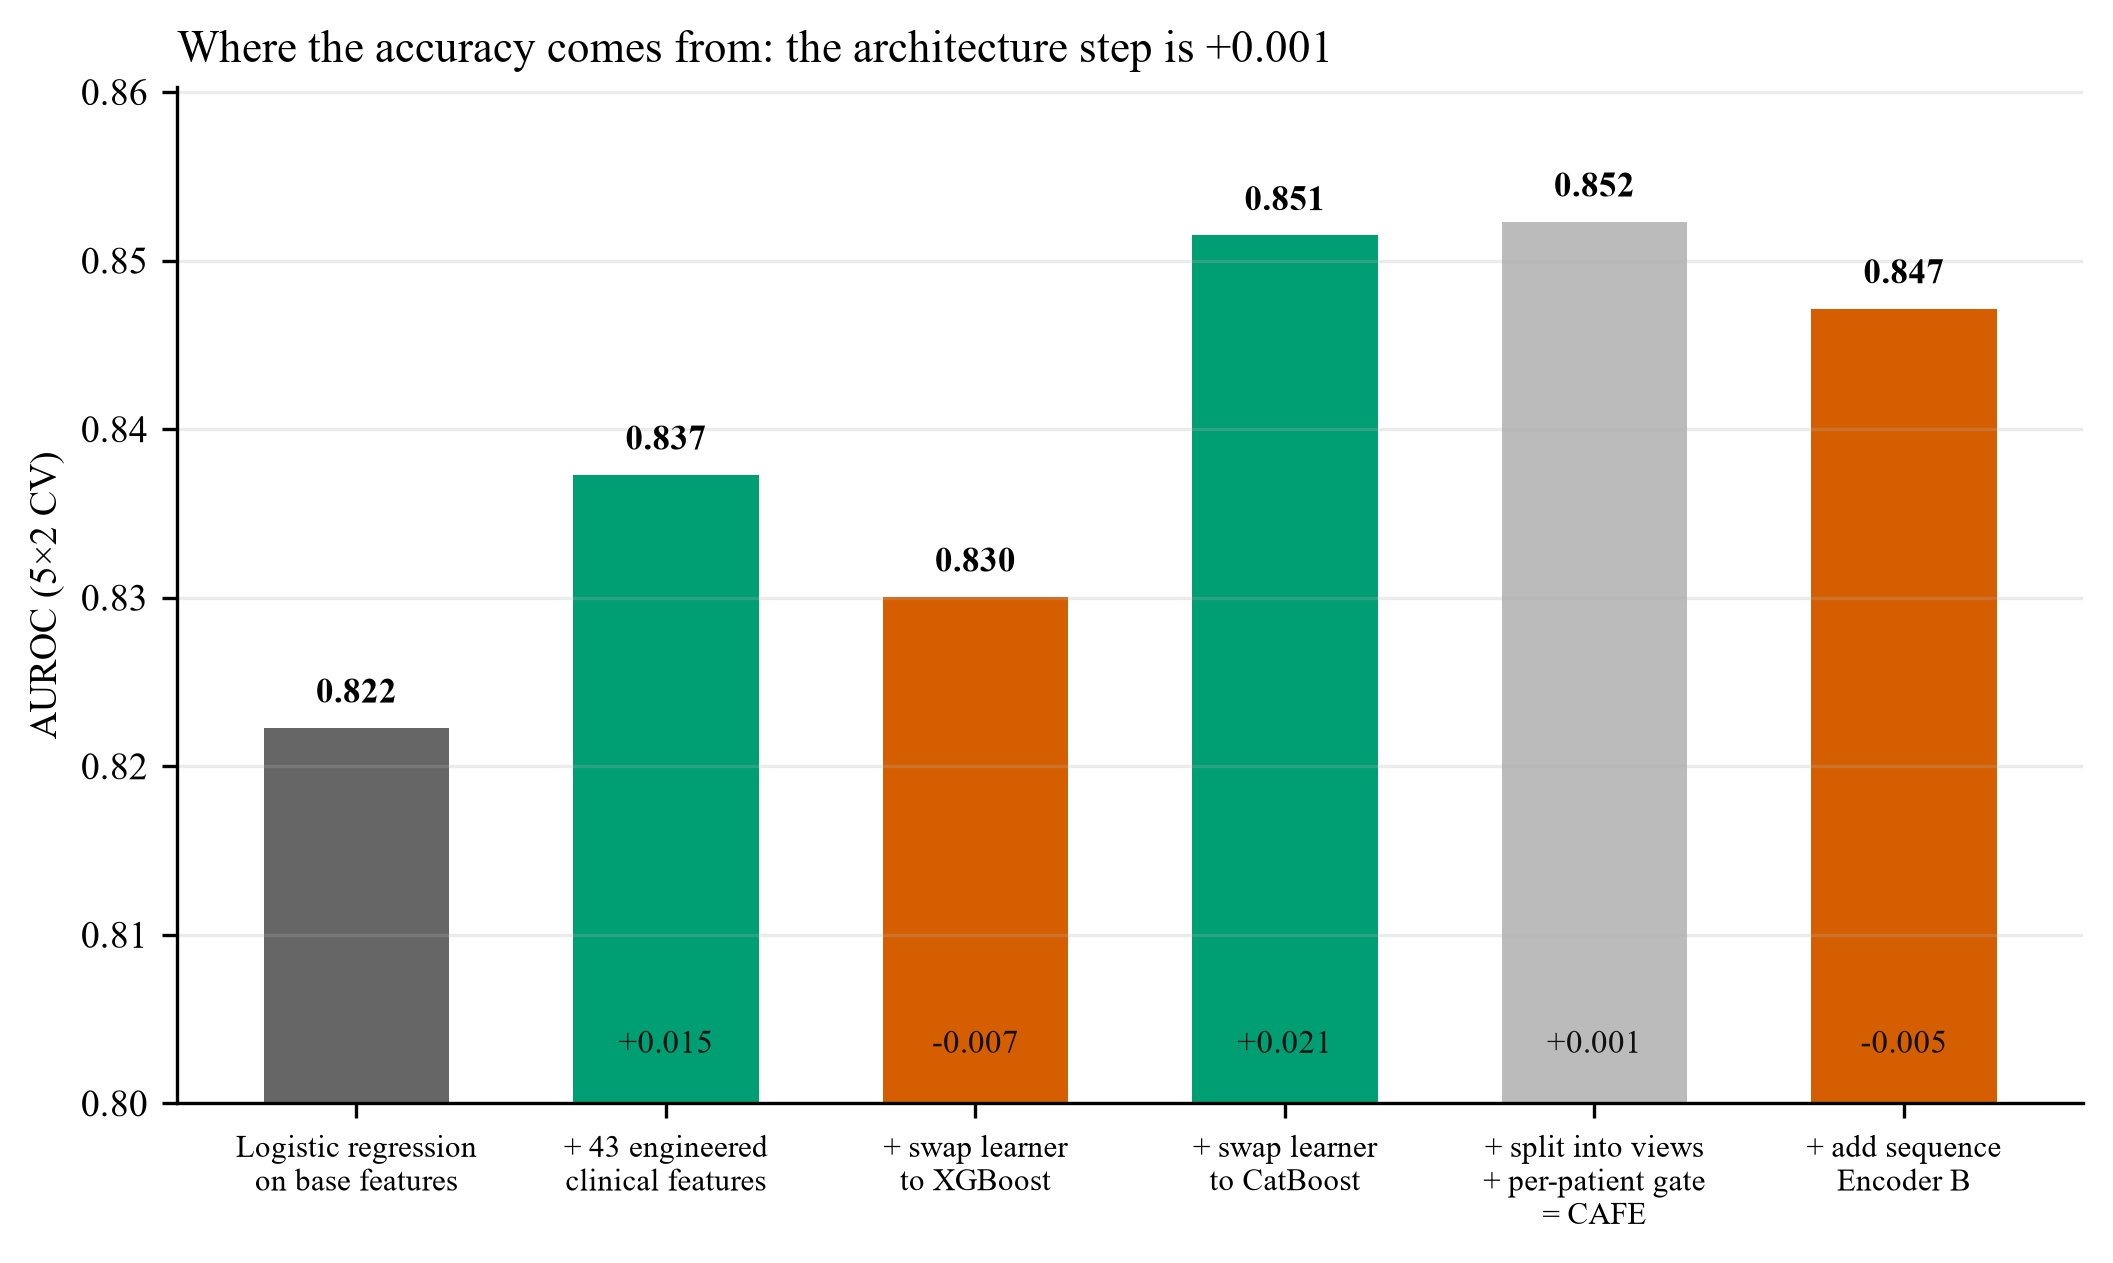

In [3]:
# Keyed by the manuscript's figure number, which is not the alphabetical file order.
FIGURES = {
    1: ("fig_cafe_calibration.png", mcf.fig_calibration),
    2: ("fig_cafe_decision_curve.png", mcf.fig_decision_curve),
    3: ("fig_cafe_shap.png", mcf.fig_shap),
    4: ("fig_cafe_accuracy_vs_cost.png", mcf.fig_accuracy_vs_cost),
    5: ("fig_cafe_ablation.png", mcf.fig_ablation),
}

figure_paths = {}
for n, (name, build) in FIGURES.items():
    build()
    figure_paths[n] = FIGS / name

for n, path in figure_paths.items():
    display(Markdown(f"**[FIGURE {n} HERE]** &rarr; `{path.relative_to(REPO)}`"))
    display(Image(filename=str(path), width=620))

## 3 · Reproducibility check — re-render and compare bytes

Hashes every PNG, renders the whole set a second time, and asserts the hashes are unchanged.
If any number could drift between runs, this cell fails.

In [4]:
before = {p.relative_to(REPO).as_posix(): sha(p) for p in sorted(FIGS.rglob("*.png"))}

again = mct.load()
for build in mct.BUILDERS:
    build(again)
for _, build in FIGURES.values():
    build()

after = {p.relative_to(REPO).as_posix(): sha(p) for p in sorted(FIGS.rglob("*.png"))}
drift = [k for k in before if before[k] != after.get(k)]

print(f"{len(before)} images re-rendered")
print(f"byte-identical : {len(before) - len(drift)}")
print(f"drifted        : {len(drift)}  {drift if drift else ''}")
assert not drift, f"non-reproducible output: {drift}"
print("\nOK -- a second run produced exactly the same images, so the numbers cannot move.")

15 images re-rendered
byte-identical : 15
drifted        : 0  

OK -- a second run produced exactly the same images, so the numbers cannot move.


## 4 · Verify the rendered numbers against the manuscript

`verify_cafe_manuscript.py` recomputes every quantitative claim in
`CAFE_Hybrid_Manuscript.md` and `CAFE_Tables_and_Figures.md` from the same CSVs and exits 1 on
any drift. If a table image and the paper ever disagree, this is what catches it.

In [5]:
proc = subprocess.run(
    [sys.executable, str(STUDY / "verify_cafe_manuscript.py")],
    cwd=REPO,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
)
print(proc.stdout[-2500:] or proc.stderr[-2500:])
assert proc.returncode == 0, f"manuscript verification FAILED (exit {proc.returncode})"
print("\nOK -- every number in the manuscript matches its source file.")

checked 163 numbers against the source CSVs
ALL NUMBERS IN CAFE_Hybrid_Manuscript.md + CAFE_Tables_and_Figures.md MATCH THEIR SOURCE FILES.


OK -- every number in the manuscript matches its source file.


## 5 · Where each image goes in the Word document

Open `CAFE_Hybrid_TemplateFormat.docx`, search for the marker in the left column, and replace
that placeholder paragraph with the image. Tables span both columns; the figures fit either a
single column (3.25 in) or the full width (6.8 in).

In [6]:
from PIL import Image as PILImage


def dims(path):
    with PILImage.open(path) as im:
        return f"{im.width}x{im.height}"


rows = [
    {
        "placeholder": f"[TABLE {n} HERE]",
        "image": p.relative_to(REPO).as_posix(),
        "pixels": dims(p),
        "suggested width in Word": "6.8 in (full page)",
    }
    for n, p in table_paths.items()
] + [
    {
        "placeholder": f"[FIGURE {n} HERE]",
        "image": p.relative_to(REPO).as_posix(),
        "pixels": dims(p),
        "suggested width in Word": "3.25 in (one column)",
    }
    for n, p in figure_paths.items()
]
pd.DataFrame(rows)

,placeholder,image,pixels,suggested width in Word
0,[TABLE 1 HERE],figures/cafe/tables/table01_feature_families.png,1738x1095,6.8 in (full page)
1,[TABLE 2 HERE],figures/cafe/tables/table02_encoder_specs.png,1727x620,6.8 in (full page)
2,[TABLE 3 HERE],figures/cafe/tables/table03_discrimination_cal...,1773x677,6.8 in (full page)
3,[TABLE 4 HERE],figures/cafe/tables/table04_engineered_feature...,1692x624,6.8 in (full page)
4,[TABLE 5 HERE],figures/cafe/tables/table05_encoder_b_ablation...,1622x638,6.8 in (full page)
5,[TABLE 6 HERE],figures/cafe/tables/table06_decision_curve.png,1576x677,6.8 in (full page)
6,[TABLE 7 HERE],figures/cafe/tables/table07_operating_point.png,1738x638,6.8 in (full page)
7,[TABLE 8 HERE],figures/cafe/tables/table08_shap_top15.png,1169x1168,6.8 in (full page)
8,[TABLE 9 HERE],figures/cafe/tables/table09_cost.png,1457x915,6.8 in (full page)
9,[TABLE 10 HERE],figures/cafe/tables/table10_ablation_decomposi...,1378x690,6.8 in (full page)
